# 2 — Random forest: is there nonlinear structure linking the light curves to age?

The linear notebook asks whether each feature tracks age monotonically. A forest can find
interactions and thresholds that no single correlation shows — but it will just as happily
learn "this is an LMC cluster, LMC clusters are young", which is not what we want to know.

So the design is a **nested model comparison** rather than a single fit:

| model | features | what it measures |
|---|---|---|
| **nuisance-only** | galaxy, cadence, sectors, length, noise floor, brightness, radius, position | how much of age is predictable from observing setup and which galaxy alone |
| **features-only** | the light-curve statistics | how much the measurements predict, confounding included |
| **full** | both | whether the light curves add anything *beyond* the nuisances |

**The number that matters is full − nuisance-only.** If adding every light-curve statistic does
not improve out-of-sample prediction over knowing the galaxy and the observing setup, then the
light curves carry no usable age information at this precision.

Two further guards:
* **Grouped/repeated CV** so no cluster appears in both train and test, and the score is not one
  lucky split.
* **A target-shuffled null** — ages permuted within galaxy — to show what ΔR² this pipeline
  produces from noise alone. With ~348 clusters and ~23 features that floor is not at zero.

> **Kernel:** `TESS_GP` (scikit-learn 1.9.1 installed 2026-09-23).

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))
import analysis_utils as A

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RepeatedKFold, GroupKFold
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

GT = '/astro/users/cgwill/TESS_Cluster_Age_ML/GenerateTable_CGW/data'
CANDIDATES = [
    f'{GT}/cluster_table_Sep23_all_combos_le3sectors.pkl',
    f'{GT}/cluster_table_Sep21_3sectorcombos_real_nofallback.pkl',
]
TABLE = next(p for p in CANDIDATES if os.path.exists(p))
SEED = 0
print('using', os.path.basename(TABLE))
pd.set_option('display.width', 220)
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})

using cluster_table_Sep23_all_combos_le3sectors.pkl


In [2]:
rows = A.load_rows(TABLE)
meta = A.cluster_metadata()
clusters = A.cluster_table(rows, meta=meta)

FEATURES  = [c for c, _, _ in A.feature_columns(rows)]
NUISANCES = [n for n, _, _ in A.NUISANCE_SPEC if n in clusters.columns]

X_nuis = A.design_matrix(clusters, NUISANCES, add_const=False)
X_feat = clusters[FEATURES].apply(pd.to_numeric, errors='coerce')
X_full = pd.concat([X_nuis, X_feat], axis=1)
y = clusters.age.values
# Redundant columns split a family's importance between its members, so each looks weak.
# Group them (age-free clustering on feature-feature correlation) and permute by block below.
reliability = A.feature_reliability(rows)
families = A.feature_families(clusters, FEATURES, threshold=0.8, reliability=reliability)
FAMILY_OF = families.set_index('feature').family.to_dict()
print(f'{len(clusters)} clusters | nuisance cols {X_nuis.shape[1]} | feature cols {X_feat.shape[1]}'
      f' in {families.family.nunique()} families')
print('missing values per feature (forest sees a median imputation):')
display(X_feat.isna().sum()[lambda s: s > 0].to_frame('n_missing').T)

17233 rows, 348 clusters from cluster_table_Sep23_all_combos_le3sectors.pkl
rows per cluster: median 3, max 409


348 clusters | nuisance cols 10 | feature cols 23 in 12 families
missing values per feature (forest sees a median imputation):


,excess_var,intrinsic_std,intrinsic_rms,gp_sigma_max,gp_period_strongest,gp_Q_strongest
n_missing,7,7,7,37,37,37


## 0b · A test set nobody touches

One row per cluster here, so a plain K-fold is already grouped correctly. What it does *not*
protect against is selection by the analyst: this table has been examined many times while the
pipeline was built, and every look is a soft model choice.

So 20% of clusters are set aside now, stratified in age, and every comparison below runs on the
remaining 80%. They are scored exactly once, in §5b. Hyperparameters are fixed and never tuned,
so the CV numbers stay unbiased for *comparing* models — the holdout is there to make the final
number quotable. Notebook 3 uses `A.holdout_by_cluster` with the same seed, so the two notebooks
hold out the same clusters and their scores are directly comparable.

In [3]:
HOLD = A.holdout_by_cluster(clusters.name.values, y=y, frac=0.2, seed=SEED)
POOL = ~HOLD
clusters_p = clusters[POOL].reset_index(drop=True)
Xn_p, Xf_p, Xfull_p = X_nuis[POOL], X_feat[POOL], X_full[POOL]
y_p, y_h = y[POOL], y[HOLD]
print(f'CV pool : {POOL.sum():3d} clusters, mean age {y_p.mean():.2f} (range {y_p.min():.1f}-{y_p.max():.1f})')
print(f'holdout : {HOLD.sum():3d} clusters, mean age {y_h.mean():.2f} (range {y_h.min():.1f}-{y_h.max():.1f})')
print('origin split:', clusters[HOLD].origin.value_counts().to_dict(),
      'vs pool', clusters_p.origin.value_counts().to_dict())

CV pool : 278 clusters, mean age 8.19 (range 6.6-10.1)
holdout :  70 clusters, mean age 8.24 (range 6.4-10.1)
origin split: {'SMC': 24, 'MW': 23, 'LMC': 23} vs pool {'MW': 101, 'LMC': 95, 'SMC': 82}


## 1 · Cross-validated model comparison

One cluster = one row here, so a plain repeated K-fold already keeps clusters separate. Missing
features are median-imputed inside the CV loop (never using test-fold information).

`n_estimators` is generous and `min_samples_leaf` is not 1: with a few hundred rows, deep trees
memorise. Scores are out-of-fold, so overfitting shows up as a low score, not a high one.

In [4]:
def make_forest(seed=SEED):
    return Pipeline([('impute', SimpleImputer(strategy='median')),
                     ('rf', RandomForestRegressor(n_estimators=600, min_samples_leaf=3,
                                                  max_features='sqrt', random_state=seed,
                                                  n_jobs=8))])

def cv_score(X, y, n_repeats=5, seed=SEED):
    cv = RepeatedKFold(n_splits=5, n_repeats=n_repeats, random_state=seed)
    scores = []
    for k, (tr, te) in enumerate(cv.split(X, y)):
        m = make_forest(seed + k).fit(X.iloc[tr], y[tr])
        p = m.predict(X.iloc[te])
        scores.append((r2_score(y[te], p), mean_absolute_error(y[te], p)))
    s = np.array(scores)
    return s[:, 0], s[:, 1]

results = {}
for label, X in [('nuisance-only', Xn_p), ('features-only', Xf_p), ('full', Xfull_p)]:
    r2, mae = cv_score(X, y_p)
    results[label] = dict(r2_mean=r2.mean(), r2_std=r2.std(), mae_mean=mae.mean(), r2_folds=r2)
    print(f'{label:>14}: R2 = {r2.mean():+.3f} +/- {r2.std():.3f}   MAE = {mae.mean():.3f} dex')

delta = results['full']['r2_mean'] - results['nuisance-only']['r2_mean']
print(f'\nfull - nuisance-only:  dR2 = {delta:+.3f}   <- the quantity of interest')

 nuisance-only: R2 = +0.154 +/- 0.141   MAE = 0.470 dex


 features-only: R2 = +0.131 +/- 0.109   MAE = 0.483 dex


          full: R2 = +0.200 +/- 0.099   MAE = 0.458 dex

full - nuisance-only:  dR2 = +0.046   <- the quantity of interest


## 2 · Is that improvement more than noise?

Permute ages **within galaxy** and re-run the whole comparison. This preserves the galaxy–age
association (so the nuisance model keeps its genuine skill) and destroys only the link between
the light-curve features and age. The spread of ΔR² under that null is the floor this pipeline
produces by chance.

observed dR2 +0.058 | null mean +0.011, sd 0.039 | p = 0.154


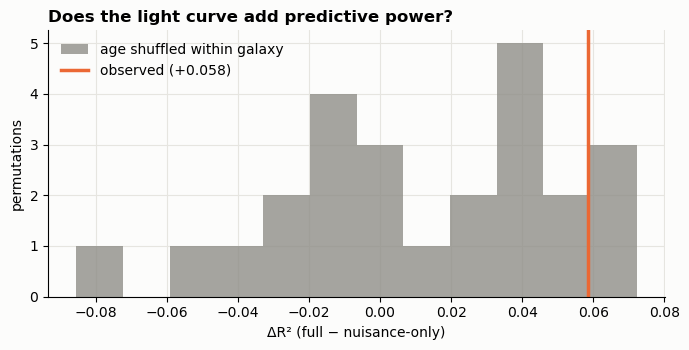

CONCLUSION —
  Nuisances alone predict age at R2 = +0.154; adding every light-curve feature gives +0.200.
  The gain is dR2 = +0.058 against a shuffled-age null of +0.011 +/- 0.039 (p = 0.154).
  No detectable improvement: at this precision the light-curve statistics add nothing
  beyond knowing the galaxy and the observing setup. That bounds any model on this feature set.


In [5]:
def delta_r2(X_n, X_f, y, seed):
    r2n, _ = cv_score(X_n, y, n_repeats=2, seed=seed)
    r2f, _ = cv_score(pd.concat([X_n, X_f], axis=1), y, n_repeats=2, seed=seed)
    return r2f.mean() - r2n.mean()

N_PERM = 25          # raise to 100+ for a publication number; each costs a full CV
rng = np.random.default_rng(SEED)
obs = delta_r2(Xn_p, Xf_p, y_p, SEED)
null = []
for i in range(N_PERM):
    y_perm = y_p.copy()
    for o in clusters_p.origin.unique():
        idx = np.where(clusters_p.origin.values == o)[0]
        y_perm[idx] = rng.permutation(y_p[idx])
    null.append(delta_r2(Xn_p, Xf_p, y_perm, SEED + 100 + i))
null = np.array(null)
p = (np.sum(null >= obs) + 1) / (len(null) + 1)
print(f'observed dR2 {obs:+.3f} | null mean {null.mean():+.3f}, sd {null.std():.3f} | p = {p:.3f}')

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(null, bins=12, color='#8f8e88', alpha=.8, label='age shuffled within galaxy')
ax.axvline(obs, color='#eb6834', lw=2.5, label=f'observed ({obs:+.3f})')
ax.set(xlabel='ΔR² (full − nuisance-only)', ylabel='permutations')
ax.set_title('Does the light curve add predictive power?', loc='left', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

print('CONCLUSION —')
print(f'  Nuisances alone predict age at R2 = {results["nuisance-only"]["r2_mean"]:+.3f}; adding every '
      f'light-curve feature gives {results["full"]["r2_mean"]:+.3f}.')
print(f'  The gain is dR2 = {obs:+.3f} against a shuffled-age null of {null.mean():+.3f} +/- {null.std():.3f} '
      f'(p = {p:.3f}).')
if p < 0.05 and obs > 0:
    print('  The light curves carry age information beyond galaxy and observing setup — check the')
    print('  per-galaxy table below before believing it is astrophysical.')
else:
    print('  No detectable improvement: at this precision the light-curve statistics add nothing')
    print('  beyond knowing the galaxy and the observing setup. That bounds any model on this feature set.')


## 3 · Which features carry it

**Block permutation importance on held-out folds.** Two deliberate choices:

* *Permutation, not the forest's impurity importance* — impurity importance is biased toward
  high-cardinality continuous features and is measured in sample, so it rewards overfitting.
* *Whole families permuted together* — with `excess_var` and `intrinsic_std` correlated at
  ρ = 0.99, permuting one changes nothing because the other still carries the information, and
  both look unimportant. Permuting the block measures what that quantity is worth.

,block,kind,importance,sd
9,feature: sigma_mad,light curve,0.1252,0.0735
4,nuisance: log_med_err_frac,nuisance,0.0250,0.0202
10,feature: stetson_j_gap_aware,light curve,0.0212,0.0180
6,nuisance: cluster_radius,nuisance,0.0171,0.0186
8,nuisance: gal_b,nuisance,0.0142,0.0134
18,feature: gp_period_strongest,light curve,0.0093,0.0054
11,feature: mean_median_offset,light curve,0.0067,0.0161
7,nuisance: dec,nuisance,0.0047,0.0056
3,nuisance: log_n_points,nuisance,0.0045,0.0100
2,nuisance: n_sectors,nuisance,0.0039,0.0086


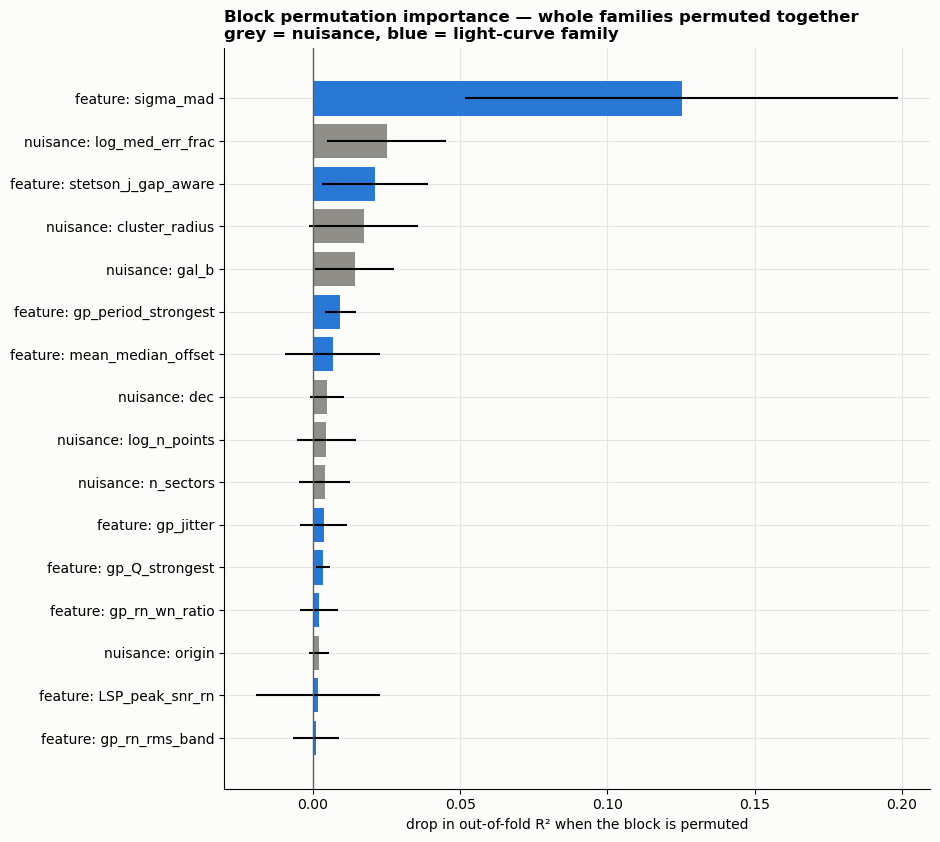

CONCLUSION —
  Top block overall: feature: sigma_mad (+0.1252).
  Best light-curve family: sigma_mad (+0.1252); best nuisance: log_med_err_frac (+0.0250).
  Summed importance — light curve +0.1731 vs nuisance +0.0694.
  Importance near zero or negative means permuting that block does not hurt prediction.


In [6]:
# Block permutation importance: permute a whole family at once.
# Permuting one column of a correlated pair changes nothing -- its twin still carries the
# information -- so single-column importance makes every redundant feature look useless.
# Families are permuted together; nuisances are permuted individually (they are not redundant
# in the same way), and 'origin' dummies are treated as one block.
from collections import defaultdict

def blocks_of(columns):
    out = defaultdict(list)
    for c in columns:
        if c in FAMILY_OF:
            out[f'feature: {FAMILY_OF[c]}'].append(c)
        elif c.startswith('origin_'):
            out['nuisance: origin'].append(c)
        else:
            out[f'nuisance: {c}'].append(c)
    return dict(out)

def block_permutation_importance(model, X, y, blocks, n_repeats=8, seed=0):
    rng = np.random.default_rng(seed)
    base = r2_score(y, model.predict(X))
    out = {}
    for name, cols in blocks.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            perm = rng.permutation(len(Xp))
            Xp[cols] = Xp[cols].to_numpy()[perm]        # same permutation for the whole block
            drops.append(base - r2_score(y, model.predict(Xp)))
        out[name] = np.mean(drops)
    return out

BLOCKS = blocks_of(Xfull_p.columns)
cv = RepeatedKFold(n_splits=5, n_repeats=2, random_state=SEED)
imp = defaultdict(list)
for k, (tr, te) in enumerate(cv.split(Xfull_p, y_p)):
    m = make_forest(SEED + k).fit(Xfull_p.iloc[tr], y_p[tr])
    for name, val in block_permutation_importance(m, Xfull_p.iloc[te], y_p[te], BLOCKS,
                                                  seed=SEED + k).items():
        imp[name].append(val)
impdf = pd.DataFrame({'block': list(imp), 'importance': [np.mean(v) for v in imp.values()],
                      'sd': [np.std(v) for v in imp.values()]})
impdf['kind'] = np.where(impdf.block.str.startswith('feature'), 'light curve', 'nuisance')
impdf['members'] = impdf.block.map(lambda b: ', '.join(BLOCKS[b]))
impdf = impdf.sort_values('importance', ascending=False)
display(impdf[['block', 'kind', 'importance', 'sd']].head(15).round(4))

fig, ax = plt.subplots(figsize=(9.5, 0.42 * min(len(impdf), 16) + 1.8))
t = impdf.head(16).iloc[::-1]
ax.barh(t.block, t.importance, xerr=t.sd,
        color=np.where(t.kind == 'nuisance', '#8f8e88', '#2a78d6'))
ax.axvline(0, color='#5f5e5a', lw=1)
ax.set(xlabel='drop in out-of-fold R² when the block is permuted')
ax.set_title('Block permutation importance — whole families permuted together\n'
             'grey = nuisance, blue = light-curve family', loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

lc = impdf[impdf.kind == 'light curve']; nu = impdf[impdf.kind == 'nuisance']
print('CONCLUSION —')
print(f'  Top block overall: {impdf.iloc[0].block} ({impdf.iloc[0].importance:+.4f}).')
print(f'  Best light-curve family: {lc.iloc[0].block.replace("feature: ", "")} ({lc.iloc[0].importance:+.4f}); '
      f'best nuisance: {nu.iloc[0].block.replace("nuisance: ", "")} ({nu.iloc[0].importance:+.4f}).')
print(f'  Summed importance — light curve {lc.importance.sum():+.4f} vs nuisance {nu.importance.sum():+.4f}.')
print('  Importance near zero or negative means permuting that block does not hurt prediction.')


## 4 · Does it survive inside a single galaxy?

The sharpest test of "is this just galaxy?": train and test **within one galaxy at a time**. The
MW is the only subsample with a wide age range, so it carries most of the weight; the LMC spans
about 2 dex of age at most and may be unable to show anything.

In [7]:
per_gal = []
for o, g in clusters_p.groupby('origin'):
    if len(g) < 60:
        per_gal.append(dict(origin=o, n=len(g), note='too few clusters')); continue
    Xn = A.design_matrix(g, [n for n in NUISANCES if n != 'origin'], add_const=False)
    Xf = g[FEATURES].apply(pd.to_numeric, errors='coerce')
    yy = g.age.values
    r2n, _ = cv_score(Xn, yy, n_repeats=3)
    r2b, _ = cv_score(pd.concat([Xn, Xf], axis=1), yy, n_repeats=3)
    per_gal.append(dict(origin=o, n=len(g), age_range=g.age.max() - g.age.min(),
                        r2_nuisance=r2n.mean(), r2_full=r2b.mean(), dR2=r2b.mean() - r2n.mean()))
display(pd.DataFrame(per_gal).round(3))

,origin,n,age_range,r2_nuisance,r2_full,dR2
0,LMC,95,1.90,0.359,0.544,0.185
1,MW,101,3.50,0.009,0.003,-0.007
2,SMC,82,2.59,-0.052,0.128,0.181


## 5 · What the forest actually learned

Partial dependence for the strongest light-curve features. Read these as "the model's average
response", not as a physical relation: with correlated features, partial dependence can imply a
dependence the data do not support on their own. The rug shows where clusters actually are —
ignore the curve where the rug is empty.

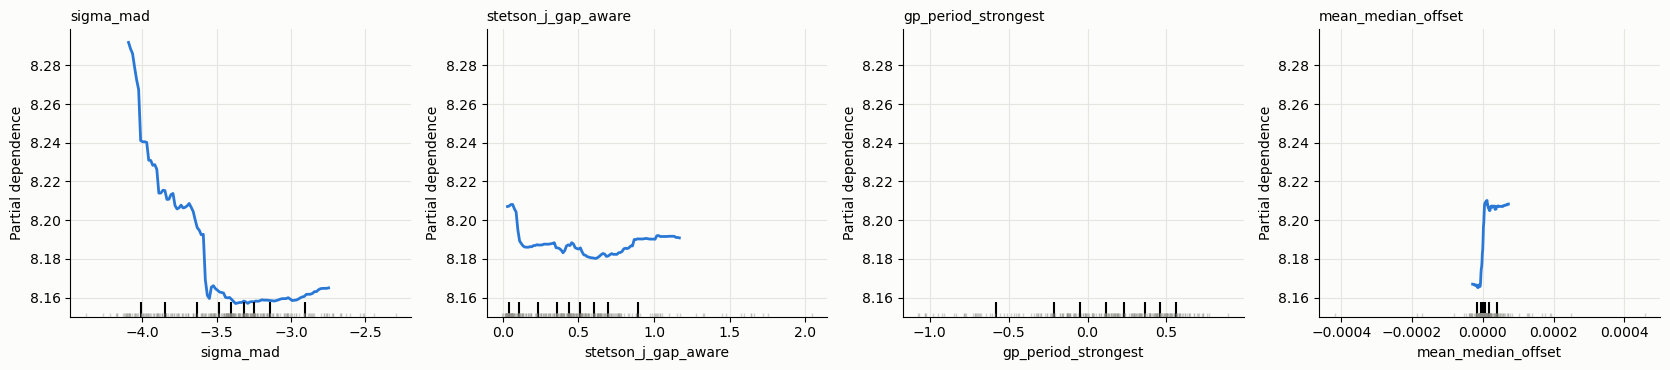

In [8]:
# representative member of each top light-curve family
top_fams = [b.replace('feature: ', '') for b in impdf[impdf.kind == 'light curve'].block][:4]
top_feats = [f for f in top_fams if f in X_full.columns]
if top_feats:
    m = make_forest().fit(Xfull_p, y_p)
    fig, axs = plt.subplots(1, len(top_feats), figsize=(4.2 * len(top_feats), 3.8))
    PartialDependenceDisplay.from_estimator(m, Xfull_p, top_feats, ax=np.atleast_1d(axs),
                                            line_kw={'color': '#2a78d6', 'lw': 2})
    for ax, f in zip(np.atleast_1d(axs), top_feats):
        vals = Xfull_p[f].dropna().values
        ax.plot(vals, np.full_like(vals, ax.get_ylim()[0]), '|', color='#8f8e88', alpha=.4, ms=6)
        ax.set_title(f, fontsize=10, loc='left')
    plt.tight_layout(); plt.show()
else:
    print('no light-curve feature made the top of the importance list')

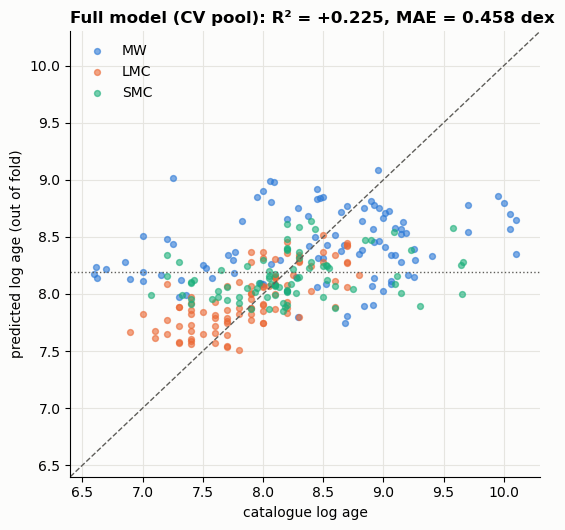

dotted line = predicting the mean age for everyone (R² = 0 by construction)
CONCLUSION —
  Out-of-fold MAE is 0.458 dex, against 0.543 dex for always predicting the mean age.
  Residual scatter 0.611 dex; the model spans predictions 7.51-9.09 for true ages 6.60-10.10.
  A cloud compressed toward the mean is the usual signature of weak features, not of a bug.


In [9]:
# Predicted vs true, full model, out of fold
cv = RepeatedKFold(n_splits=5, n_repeats=1, random_state=SEED)
pred = np.full(len(y_p), np.nan)
for k, (tr, te) in enumerate(cv.split(Xfull_p, y_p)):
    pred[te] = make_forest(SEED + k).fit(Xfull_p.iloc[tr], y_p[tr]).predict(Xfull_p.iloc[te])
fig, ax = plt.subplots(figsize=(5.6, 5.4))
colours = {'MW': '#2a78d6', 'LMC': '#eb6834', 'SMC': '#1baf7a'}
for o in clusters_p.origin.unique():
    i = np.where(clusters_p.origin.values == o)[0]      # positional, not label-based
    ax.scatter(y_p[i], pred[i], s=18, alpha=.6, color=colours.get(o, '#8f8e88'), label=o)
lims = [np.nanmin(y_p) - .2, np.nanmax(y_p) + .2]
ax.plot(lims, lims, ls='--', color='#5f5e5a', lw=1)
ax.axhline(np.mean(y_p), color='#5f5e5a', lw=1, ls=':')
ax.set(xlabel='catalogue log age', ylabel='predicted log age (out of fold)', xlim=lims, ylim=lims)
ax.set_title(f'Full model (CV pool): R² = {r2_score(y_p, pred):+.3f}, MAE = {mean_absolute_error(y_p, pred):.3f} dex',
             loc='left', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()
print('dotted line = predicting the mean age for everyone (R² = 0 by construction)')

resid = y_p - pred
print('CONCLUSION —')
print(f'  Out-of-fold MAE is {mean_absolute_error(y_p, pred):.3f} dex, against {np.abs(y_p - y_p.mean()).mean():.3f} dex '
      'for always predicting the mean age.')
print(f'  Residual scatter {resid.std():.3f} dex; the model spans predictions '
      f'{pred.min():.2f}-{pred.max():.2f} for true ages {y_p.min():.2f}-{y_p.max():.2f}.')
print('  A cloud compressed toward the mean is the usual signature of weak features, not of a bug.')


## 5b · The one look at the held-out clusters

Trained on the pool, scored once on the 20% held out in §0b. Nothing in §1–§5 saw these
clusters, so this is the number to quote.

 nuisance-only: holdout R2 = +0.282   MAE = 0.516 dex


 features-only: holdout R2 = +0.013   MAE = 0.586 dex


          full: holdout R2 = +0.113   MAE = 0.554 dex


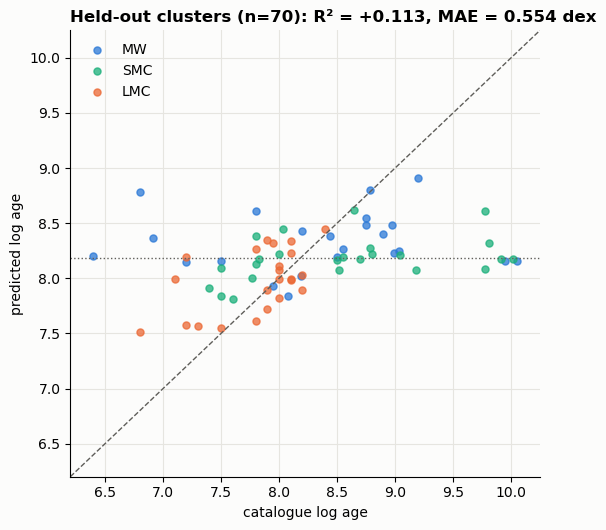

CONCLUSION —
  Holdout: full +0.113 vs nuisance-only +0.282, so dR2 = -0.169 (CV pool gave +0.046).
  The holdout gain is smaller than the CV gain. With only ~70 held-out clusters some of
  that is sampling noise, but it is the direction expected if choices made while building
  the pipeline were tuned to the pool. Quote the holdout number.


In [10]:
hold_scores = {}
for label, Xp, Xh in [('nuisance-only', Xn_p, X_nuis[HOLD]),
                      ('features-only', Xf_p, X_feat[HOLD]),
                      ('full',          Xfull_p, X_full[HOLD])]:
    ph = make_forest(SEED).fit(Xp, y_p).predict(Xh)
    hold_scores[label] = dict(r2=r2_score(y_h, ph), mae=mean_absolute_error(y_h, ph), pred=ph)
    print(f'{label:>14}: holdout R2 = {hold_scores[label]["r2"]:+.3f}   MAE = {hold_scores[label]["mae"]:.3f} dex')
d_hold = hold_scores['full']['r2'] - hold_scores['nuisance-only']['r2']

fig, ax = plt.subplots(figsize=(5.6, 5.4))
ph = hold_scores['full']['pred']
for o in clusters[HOLD].origin.unique():
    i = np.where(clusters[HOLD].origin.values == o)[0]
    ax.scatter(y_h[i], ph[i], s=26, alpha=.75, color=colours.get(o, '#8f8e88'), label=o)
lims = [y_h.min() - .2, y_h.max() + .2]
ax.plot(lims, lims, ls='--', color='#5f5e5a', lw=1)
ax.axhline(y_p.mean(), color='#5f5e5a', lw=1, ls=':')
ax.set(xlabel='catalogue log age', ylabel='predicted log age', xlim=lims, ylim=lims)
ax.set_title(f'Held-out clusters (n={HOLD.sum()}): R² = {hold_scores["full"]["r2"]:+.3f}, '
             f'MAE = {hold_scores["full"]["mae"]:.3f} dex', loc='left', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

print('CONCLUSION —')
print(f'  Holdout: full {hold_scores["full"]["r2"]:+.3f} vs nuisance-only '
      f'{hold_scores["nuisance-only"]["r2"]:+.3f}, so dR2 = {d_hold:+.3f} '
      f'(CV pool gave {delta:+.3f}).')
if abs(d_hold - delta) < 0.05:
    print('  The holdout reproduces the cross-validated gain, so the CV estimate was not shaped')
    print('  by repeated looks at the pool.')
elif d_hold < delta:
    print('  The holdout gain is smaller than the CV gain. With only ~70 held-out clusters some of')
    print('  that is sampling noise, but it is the direction expected if choices made while building')
    print('  the pipeline were tuned to the pool. Quote the holdout number.')
else:
    print('  The holdout gain exceeds the CV gain — a favourable draw of held-out clusters. Quote')
    print('  the smaller of the two.')

In [11]:
summary = pd.DataFrame([
    dict(model=k, r2=v['r2_mean'], r2_sd=v['r2_std'], mae=v['mae_mean'],
         holdout_r2=hold_scores[k]['r2'], holdout_mae=hold_scores[k]['mae'])
    for k, v in results.items()])
summary.to_csv('results_random_forest.csv', index=False)
impdf.to_csv('results_rf_importances.csv', index=False)   # block-level
display(summary.round(3))
print(f'dR2 (full - nuisance) = {delta:+.3f} on the CV pool, {d_hold:+.3f} on the holdout; '
      f'permutation p = {p:.3f}')
print('wrote results_random_forest.csv, results_rf_importances.csv')

,model,r2,r2_sd,mae,holdout_r2,holdout_mae
0,nuisance-only,0.154,0.141,0.470,0.282,0.516
1,features-only,0.131,0.109,0.483,0.013,0.586
2,full,0.200,0.099,0.458,0.113,0.554


dR2 (full - nuisance) = +0.046 on the CV pool, -0.169 on the holdout; permutation p = 0.154
wrote results_random_forest.csv, results_rf_importances.csv


## 6 · Reading this honestly

* **ΔR² near zero with p ≳ 0.05** → the light-curve statistics add nothing beyond galaxy and
  observing setup. Combined with notebook 1, that is a clear negative result and worth stating:
  it bounds what any model on this feature set can do.
* **ΔR² clearly above the null** → check §4 before believing it. A signal that disappears inside
  every galaxy is a galaxy effect wearing a disguise.
* **Nuisances dominating the importance ranking** is expected and fine — it is exactly why the
  comparison is nested rather than a single fit.

Limits that no amount of modelling fixes here: ~348 clusters is a small sample for a 20-feature
forest, so ΔR² has a wide error bar; catalogue ages carry their own uncertainty, which caps the
attainable R²; and the LMC contributes many clusters over a narrow age range, so it adds
statistical weight without adding much age leverage.